<a href="https://colab.research.google.com/github/harpreetsingh171190-cmyk/CADmium-Engine-Pro/blob/main/CADmium_All_Features_Complete_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CADmium — P0 Engineering Notebook (Expanded)

**Purpose:** executable reference prototypes for the first four P0 areas:

1. **Parametric Sketching Engine** — 2D points, segments, constraints and numerical solving.
2. **Solid Modeling Operations** — prismatic extrusion and same-height profile Boolean operations, plus a revolution demo.
3. **Feature History and Editing** — ordered feature tree, parameter edits, rebuild and undo/redo snapshots.
4. **Save, Load and Export** — versioned JSON project save/load, SVG profile export, and STL/OBJ mesh export.

> **Important project fit:** this is a Python reference/prototype notebook. It does not modify CADmium's Rust/WASM engine or automatically integrate with the SvelteKit/Tauri application. Use the acceptance checklists to port validated behavior into the repository. The solid Boolean prototype is intentionally limited to 2D profile operations extruded to a common height; it is not a production B-rep kernel. STEP export is not implemented by this notebook.

## P0 architecture

```mermaid
flowchart TD
  A[Parametric Sketch] --> B[Constraint Solver]
  B --> C[Validated 2D Profile]
  C --> D[Feature History]
  D --> E[Solid Operations]
  E --> F[Preview Mesh]
  D --> G[Versioned Project JSON]
  F --> H[STL / OBJ Export]
  C --> I[SVG Profile Export]
```


## 1. Install / import dependencies

Google Colab normally has NumPy, SciPy, and Matplotlib installed. This cell installs them if needed.

In [1]:
%pip -q install numpy scipy matplotlib

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
print("Dependencies ready")

Dependencies ready


## 2. Parametric sketch model

Coordinates are stored as a flat vector `[x0, y0, x1, y1, ...]`. Constraints return residuals that should approach zero.

In [2]:
from dataclasses import dataclass, field
from typing import List, Tuple, Dict, Any

@dataclass
class Segment:
    a: int  # index of start point
    b: int  # index of end point
    name: str = "segment"

@dataclass
class ConstraintSpec:
    kind: str
    data: dict

@dataclass
class ParametricSketch:
    points: List[Tuple[float, float]] = field(default_factory=list)
    segments: List[Segment] = field(default_factory=list)
    constraints: List[ConstraintSpec] = field(default_factory=list)

    def add_point(self, x: float, y: float) -> int:
        self.points.append((float(x), float(y)))
        return len(self.points) - 1

    def add_segment(self, a: int, b: int, name: str = "segment") -> int:
        self._check_point(a); self._check_point(b)
        if a == b:
            raise ValueError("A segment must use two different point indices")
        self.segments.append(Segment(a, b, name))
        return len(self.segments) - 1

    def add_constraint(self, kind: str, **data):
        allowed = {"horizontal", "vertical", "coincident", "fixed_point", "length", "equal_length"}
        if kind not in allowed:
            raise ValueError(f"Unsupported constraint: {kind}")
        self.constraints.append(ConstraintSpec(kind, data))

    def _check_point(self, i):
        if not isinstance(i, int) or i < 0 or i >= len(self.points):
            raise IndexError(f"Invalid point index: {i}")

    def initial_vector(self):
        if not self.points:
            raise ValueError("Sketch needs at least one point")
        return np.asarray(self.points, dtype=float).reshape(-1)

    @staticmethod
    def _xy(v, i):
        return v[2*i], v[2*i+1]

    def residuals(self, v):
        r = []
        for c in self.constraints:
            d = c.data
            if c.kind == "horizontal":
                seg = self.segments[d["segment"]]
                _, ay = self._xy(v, seg.a); _, by = self._xy(v, seg.b)
                r.append(by - ay)
            elif c.kind == "vertical":
                seg = self.segments[d["segment"]]
                ax, _ = self._xy(v, seg.a); bx, _ = self._xy(v, seg.b)
                r.append(bx - ax)
            elif c.kind == "coincident":
                ax, ay = self._xy(v, d["point_a"])
                bx, by = self._xy(v, d["point_b"])
                r.extend([ax-bx, ay-by])
            elif c.kind == "fixed_point":
                x, y = self._xy(v, d["point"])
                r.extend([x-d["x"], y-d["y"]])
            elif c.kind == "length":
                seg = self.segments[d["segment"]]
                ax, ay = self._xy(v, seg.a); bx, by = self._xy(v, seg.b)
                r.append(math.hypot(bx-ax, by-ay) - float(d["value"]))
            elif c.kind == "equal_length":
                s1 = self.segments[d["segment_a"]]
                s2 = self.segments[d["segment_b"]]
                a1, b1 = self._xy(v, s1.a), self._xy(v, s1.b)
                a2, b2 = self._xy(v, s2.a), self._xy(v, s2.b)
                l1 = math.hypot(b1[0]-a1[0], b1[1]-a1[1])
                l2 = math.hypot(b2[0]-a2[0], b2[1]-a2[1])
                r.append(l1-l2)
        return np.asarray(r, dtype=float)

    def solve(self, tolerance=1e-9, max_nfev=5000):
        x0 = self.initial_vector()
        if not self.constraints:
            return {"success": True, "message": "No constraints; geometry unchanged", "vector": x0,
                    "max_residual": 0.0, "cost": 0.0, "evaluations": 0}
        result = least_squares(self.residuals, x0, xtol=tolerance, ftol=tolerance,
                               gtol=tolerance, max_nfev=max_nfev)
        residual = self.residuals(result.x)
        # 'success' means solver termination AND constraints are numerically satisfied.
        max_residual = float(np.max(np.abs(residual))) if residual.size else 0.0
        return {"success": bool(result.success and max_residual < 1e-5),
                "solver_terminated": bool(result.success), "message": result.message,
                "vector": result.x, "max_residual": max_residual,
                "cost": float(result.cost), "evaluations": int(result.nfev)}

    def apply_solution(self, vector):
        self.points = [(float(vector[2*i]), float(vector[2*i+1])) for i in range(len(self.points))]

    def report(self, vector=None):
        v = self.initial_vector() if vector is None else np.asarray(vector)
        return [{"constraint": c.kind, "residuals": self._constraint_residual(c, v)} for c in self.constraints]

    def _constraint_residual(self, constraint, v):
        # Produce per-constraint residuals without mutating the sketch.
        temp = ParametricSketch(points=self.points, segments=self.segments, constraints=[constraint])
        return temp.residuals(v).tolist()

print("ParametricSketch model defined")

ParametricSketch model defined


## 3. Visualization helper

In [3]:
def plot_sketch(sketch, vector=None, title="Parametric sketch"):
    v = sketch.initial_vector() if vector is None else np.asarray(vector, dtype=float)
    fig, ax = plt.subplots(figsize=(7, 5))
    for idx, seg in enumerate(sketch.segments):
        ax0, ay0 = sketch._xy(v, seg.a); bx0, by0 = sketch._xy(v, seg.b)
        ax.plot([ax0, bx0], [ay0, by0], marker="o", linewidth=2, label=seg.name if seg.name else f"S{idx}")
        ax.text((ax0+bx0)/2, (ay0+by0)/2, f" S{idx}")
    for i in range(len(sketch.points)):
        x, y = sketch._xy(v, i)
        ax.annotate(f"P{i} ({x:.2f}, {y:.2f})", (x, y), xytext=(5, 6), textcoords="offset points", fontsize=8)
    ax.set_title(title); ax.set_xlabel("X (model units)"); ax.set_ylabel("Y (model units)")
    ax.grid(True); ax.axis("equal")
    if sketch.segments: ax.legend(loc="best")
    plt.show()

print("Plot helper defined")

Plot helper defined


## 4. Example: fixed origin + horizontal 10-unit line

The solver adjusts the second point so the segment is horizontal and exactly 10 units long.

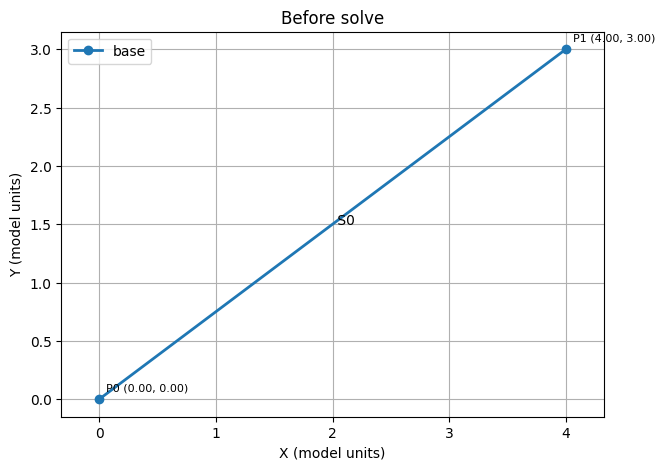

{'success': True, 'solver_terminated': True, 'message': '`gtol` termination condition is satisfied.', 'max_residual': 1.3877787807814457e-17, 'cost': 9.62964972193618e-35, 'evaluations': 4}


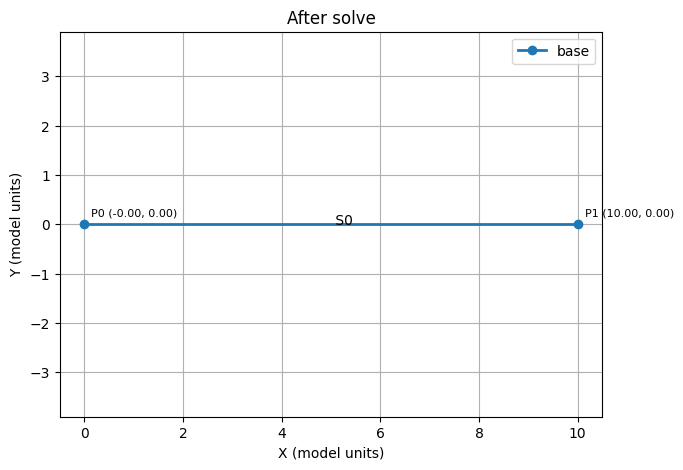

Solved points: [(-1.3877787807814457e-17, 9.860761315262648e-32), (10.0, 2.9582283945787943e-31)]
Constraint residuals: [{'constraint': 'fixed_point', 'residuals': [-1.3877787807814457e-17, 9.860761315262648e-32]}, {'constraint': 'horizontal', 'residuals': [1.9721522630525295e-31]}, {'constraint': 'length', 'residuals': [0.0]}]


In [4]:
sketch = ParametricSketch()
p0 = sketch.add_point(0, 0)
p1 = sketch.add_point(4, 3)
s0 = sketch.add_segment(p0, p1, "base")
sketch.add_constraint("fixed_point", point=p0, x=0, y=0)
sketch.add_constraint("horizontal", segment=s0)
sketch.add_constraint("length", segment=s0, value=10.0)

before = sketch.initial_vector()
plot_sketch(sketch, before, "Before solve")
solution = sketch.solve()
print({k: v for k, v in solution.items() if k != "vector"})
assert solution["success"], solution["message"]
sketch.apply_solution(solution["vector"])
plot_sketch(sketch, title="After solve")
print("Solved points:", sketch.points)
print("Constraint residuals:", sketch.report())

## 5. Example: rectangle-like closed profile

This checks coincident endpoints, horizontal/vertical constraints, and equal-length behavior. A real CAD solver should also provide robust DOF analysis and conflict diagnosis; this prototype only checks residuals.

{'success': True, 'solver_terminated': True, 'message': '`gtol` termination condition is satisfied.', 'max_residual': 2.8066438062523957e-13, 'cost': 6.566946109131389e-26, 'evaluations': 4}


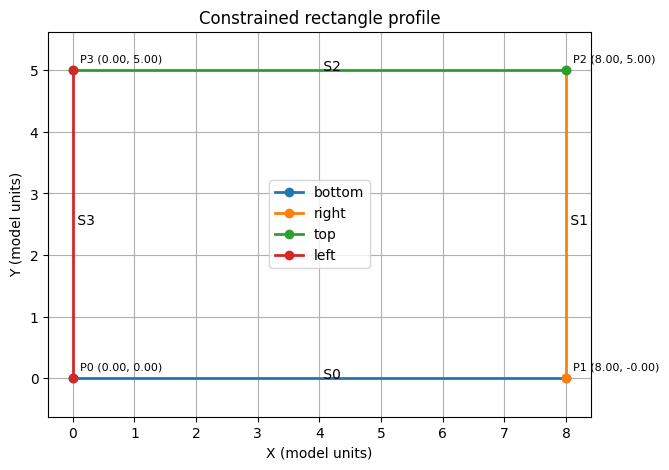

Points: [(2.541098841762901e-21, 8.470329472543003e-22), (8.000000000000052, -9.054887492343814e-14), (8.00000000000004, 5.00000000000019), (1.0443972143820042e-14, 5.0000000000000995)]
Maximum residual: 2.8066438062523957e-13


In [5]:
rect = ParametricSketch()
p0 = rect.add_point(0, 0); p1 = rect.add_point(8.5, 0.3)
p2 = rect.add_point(7.8, 5.5); p3 = rect.add_point(-0.2, 4.8)
s0 = rect.add_segment(p0, p1, "bottom")
s1 = rect.add_segment(p1, p2, "right")
s2 = rect.add_segment(p2, p3, "top")
s3 = rect.add_segment(p3, p0, "left")
rect.add_constraint("fixed_point", point=p0, x=0, y=0)
rect.add_constraint("horizontal", segment=s0)
rect.add_constraint("vertical", segment=s1)
rect.add_constraint("horizontal", segment=s2)
rect.add_constraint("vertical", segment=s3)
rect.add_constraint("length", segment=s0, value=8.0)
rect.add_constraint("length", segment=s1, value=5.0)
rect.add_constraint("equal_length", segment_a=s0, segment_b=s2)
rect.add_constraint("equal_length", segment_a=s1, segment_b=s3)

rect_result = rect.solve()
print({k: v for k, v in rect_result.items() if k != "vector"})
assert rect_result["success"], "Rectangle constraints did not converge"
rect.apply_solution(rect_result["vector"])
plot_sketch(rect, title="Constrained rectangle profile")
print("Points:", rect.points)
print("Maximum residual:", rect_result["max_residual"])

## 6. Automated regression tests

In [6]:
def run_regression_tests():
    # Test 1: fixed point + horizontal + exact length
    s = ParametricSketch()
    a = s.add_point(0, 0); b = s.add_point(2, 7)
    edge = s.add_segment(a, b)
    s.add_constraint("fixed_point", point=a, x=0, y=0)
    s.add_constraint("horizontal", segment=edge)
    s.add_constraint("length", segment=edge, value=12)
    out = s.solve()
    assert out["success"], out
    s.apply_solution(out["vector"])
    assert abs(s.points[0][0]) < 1e-5 and abs(s.points[0][1]) < 1e-5
    assert abs(s.points[1][1]) < 1e-5
    assert abs(abs(s.points[1][0] - s.points[0][0]) - 12) < 1e-5

    # Test 2: coincident points
    s2 = ParametricSketch()
    a = s2.add_point(0, 0); b = s2.add_point(5, -2)
    s2.add_constraint("coincident", point_a=a, point_b=b)
    out2 = s2.solve()
    assert out2["success"], out2
    s2.apply_solution(out2["vector"])
    assert np.linalg.norm(np.array(s2.points[0]) - np.array(s2.points[1])) < 1e-5

    # Test 3: invalid segment indices rejected
    s3 = ParametricSketch(); s3.add_point(0, 0)
    try:
        s3.add_segment(0, 3)
        raise AssertionError("Expected invalid point index to fail")
    except IndexError:
        pass

    # Test 4: unsupported constraint rejected
    try:
        s3.add_constraint("mystery_constraint")
        raise AssertionError("Expected unsupported constraint to fail")
    except ValueError:
        pass

    return "PASS: 4 regression checks"

print(run_regression_tests())

PASS: 4 regression checks


## 7. P0 acceptance checklist for CADmium proper

Use this checklist when porting the proven behavior to the repository's Rust engine. Do not mark a checkbox complete until code and tests exist in the repository.

- [ ] Define stable IDs and serializable types for sketch points, segments, and constraints.
- [ ] Preserve existing CADmium constraint API and `.cadmium` project compatibility.
- [ ] Add/verify horizontal and vertical constraints.
- [ ] Add/verify coincident point constraints.
- [ ] Add/verify fixed-point constraints.
- [ ] Add/verify segment-length and equal-length constraints.
- [ ] Return structured solver status, residuals, and iteration diagnostics.
- [ ] Detect unsatisfied/conflicting constraints instead of reporting false success.
- [ ] Add deterministic Rust unit tests for each constraint and combinations.
- [ ] Add regression fixtures for sketch edits and serialization round trips.
- [ ] Connect constraint editing and visual feedback in Svelte UI only after engine APIs are stable.
- [ ] Verify WASM/browser behavior and desktop behavior.

### Suggested repository locations

- Existing engine: `packages/cadmium/src/sketch/mod.rs`
- Existing constraints: `packages/cadmium/src/sketch/constraints.rs`
- Existing sketch UI: `applications/web/src/components/Sketch.svelte`
- Feature sketch UI: `applications/web/src/components/features/Sketch.svelte`
- Existing tests and fixtures: `packages/cadmium/src/test.rs` and `packages/cadmium/src/sketch/`

These paths are based on the uploaded ZIP's directory listing. Review the surrounding implementation before editing; this notebook does not write into those source files.

## 8. P0 Solid Modeling Operations

This section adds a **reference feature model** using Shapely 2D profiles and triangular meshes. It supports:
- Extrude a valid 2D polygon into a prismatic solid.
- New body, add, cut and intersection operations on 2D footprints **when the resulting solids share the same base Z and height**.
- A revolution preview for a radial profile (requires `trimesh`).

**Scope limitation:** profile Booleans are not general 3D Boolean operations. Complex B-rep operations, arbitrary face topology, robust fillets/chamfers and production-grade manifold guarantees belong in CADmium's real geometry kernel.

In [7]:
%pip -q install shapely trimesh

from dataclasses import dataclass, asdict
from shapely.geometry import Polygon, box, Point
from shapely.ops import triangulate
import trimesh, numpy as np, matplotlib.pyplot as plt
import json, copy, os
from pathlib import Path

print("Solid modeling dependencies ready")

Solid modeling dependencies ready


{'status': 'valid-prismatic-prototype', 'feature_count': 2, 'profile_area': 864.0, 'height': 5.0, 'mesh_volume': 4320.0, 'watertight': True}


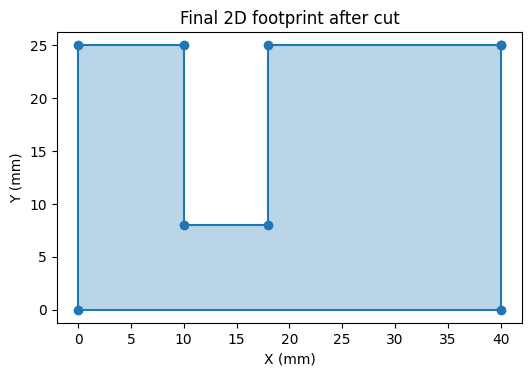

PASS: extrusion + same-height profile cut


In [8]:
def _valid_polygon(coords):
    poly = Polygon(coords)
    if poly.is_empty or not poly.is_valid or poly.area <= 1e-9:
        raise ValueError("Profile must be a valid, non-self-intersecting polygon with positive area")
    if len(poly.interiors):
        raise NotImplementedError("This prototype currently accepts profiles without holes")
    return poly

def _polygon_to_mesh(poly, height, z0=0.0):
    """Build a closed triangle mesh for a simple Shapely polygon prism."""
    if not poly.is_valid or poly.is_empty or poly.area <= 1e-9:
        raise ValueError("Cannot extrude an invalid or empty profile")
    if height <= 0:
        raise ValueError("Extrusion height must be greater than zero")
    # Triangulate and keep triangles fully inside the profile.
    tris = [t for t in triangulate(poly) if poly.covers(t.representative_point())]
    vertices, faces = [], []
    # Separate vertices per face is fine for this reference mesh; process() merges duplicates.
    for tri in tris:
        coords = list(tri.exterior.coords)[:3]
        base = len(vertices)
        vertices.extend([(x,y,z0) for x,y in coords])
        vertices.extend([(x,y,z0+height) for x,y in coords])
        faces.extend([[base,base+2,base+1], [base+3,base+4,base+5]])
    # Side quads for each exterior edge.
    ring = list(poly.exterior.coords)[:-1]
    for i, (x1,y1) in enumerate(ring):
        x2,y2 = ring[(i+1) % len(ring)]
        base = len(vertices)
        vertices.extend([(x1,y1,z0),(x2,y2,z0),(x2,y2,z0+height),(x1,y1,z0+height)])
        faces.extend([[base,base+1,base+2],[base,base+2,base+3]])
    mesh = trimesh.Trimesh(vertices=np.asarray(vertices), faces=np.asarray(faces), process=True)
    mesh.remove_unreferenced_vertices()
    return mesh

@dataclass
class SolidFeature:
    name: str
    operation: str
    params: dict
    enabled: bool = True

class P0SolidModel:
    def __init__(self):
        self.features = []
        self.profile = None
        self.height = None
        self.mesh = None
        self.status = "empty"

    def add_extrusion(self, name, profile_coords, height, operation="new"):
        if operation not in {"new", "add", "cut", "intersection"}:
            raise ValueError("operation must be new, add, cut, or intersection")
        poly = _valid_polygon(profile_coords)
        if float(height) <= 0: raise ValueError("height must be positive")
        if operation != "new":
            if self.profile is None: raise ValueError("Create a 'new' extrusion before add/cut/intersection")
            if abs(float(height)-float(self.height)) > 1e-9:
                raise ValueError("P0 profile Boolean operations require the same extrusion height")
            if operation == "add": result = self.profile.union(poly)
            elif operation == "cut": result = self.profile.difference(poly)
            else: result = self.profile.intersection(poly)
            if result.is_empty: raise ValueError("Boolean operation produced an empty profile")
            if result.geom_type != "Polygon":
                raise NotImplementedError("This prototype currently supports a single Polygon result only")
            if len(result.interiors): raise NotImplementedError("Boolean result has holes; not supported in this prototype")
            poly = result
        self.features.append(SolidFeature(name, "extrude", {"profile": [list(p) for p in list(_valid_polygon(profile_coords).exterior.coords)[:-1]], "height": float(height), "operation": operation}))
        self.profile, self.height = poly, float(height)
        self.mesh = _polygon_to_mesh(poly, self.height)
        self.status = "valid-prismatic-prototype"
        return self.mesh

    def summary(self):
        return {"status": self.status, "feature_count": len(self.features),
                "profile_area": None if self.profile is None else float(self.profile.area),
                "height": self.height, "mesh_volume": None if self.mesh is None else float(abs(self.mesh.volume)),
                "watertight": None if self.mesh is None else bool(self.mesh.is_watertight)}

# Demo: create a 40 x 25 x 5 mm plate, then cut a rectangular notch from its footprint.
solid = P0SolidModel()
solid.add_extrusion("Base plate", [(0,0),(40,0),(40,25),(0,25)], 5, "new")
solid.add_extrusion("Notch cut", [(10,8),(18,8),(18,25),(10,25)], 5, "cut")
print(solid.summary())
solid.mesh.show if False else None
fig, ax = plt.subplots(figsize=(6,4))
x,y = solid.profile.exterior.xy
ax.fill(x,y,alpha=.3); ax.plot(x,y,marker='o'); ax.set_aspect('equal'); ax.set_title('Final 2D footprint after cut'); ax.set_xlabel('X (mm)'); ax.set_ylabel('Y (mm)'); plt.show()
assert abs(solid.profile.area - (40*25 - 8*17)) < 1e-8
assert abs(solid.summary()["mesh_volume"] - solid.profile.area*5) < 1e-6
print("PASS: extrusion + same-height profile cut")

### Revolution preview

The following cell demonstrates a revolved solid from a radial/height profile. The profile's first coordinate is radius (must be non-negative) and the second is height. This is a visualization/export prototype, not a constrained sketch revolution feature in CADmium's production engine.

In [9]:
# A simple cylindrical sleeve-like revolved profile (radius, height).
revolve_profile = np.array([[8,0],[12,0],[12,20],[8,20],[8,0]], dtype=float)
if np.any(revolve_profile[:,0] < 0):
    raise ValueError("Revolution profile radius must be non-negative")
revolved_mesh = trimesh.creation.revolve(revolve_profile, sections=48)
print({"vertices": len(revolved_mesh.vertices), "faces": len(revolved_mesh.faces),
       "watertight": bool(revolved_mesh.is_watertight), "volume": float(abs(revolved_mesh.volume))})

{'vertices': 192, 'faces': 384, 'watertight': True, 'volume': 5012.205781249981}


## 9. P0 Feature History and Editing

The feature history stores ordered, serializable parameters. Editing a feature updates its parameters and rebuilds downstream features. Undo/redo use deep-copied snapshots. This demonstrates the history contract; it is not a substitute for CADmium's stable topology references or dependency graph.

In [10]:
class FeatureHistory:
    def __init__(self, base_profile, height):
        self.base_profile = [list(p) for p in base_profile]
        self.features = [{"id":"feature-001", "name":"Base extrusion", "type":"extrude",
                          "profile":self.base_profile, "height":float(height), "operation":"new", "enabled":True}]
        self.undo_stack, self.redo_stack = [], []
        self.rebuild()

    def _snapshot(self):
        return copy.deepcopy(self.features)

    def add(self, name, profile, height, operation):
        if operation not in {"new","add","cut","intersection"}: raise ValueError("Unsupported operation")
        self.undo_stack.append(self._snapshot()); self.redo_stack.clear()
        self.features.append({"id":f"feature-{len(self.features)+1:03d}", "name":name, "type":"extrude",
                              "profile":[list(p) for p in profile], "height":float(height), "operation":operation, "enabled":True})
        self.rebuild()

    def edit(self, feature_id, **changes):
        feature = next((f for f in self.features if f["id"] == feature_id), None)
        if feature is None: raise KeyError(f"Unknown feature id: {feature_id}")
        allowed = {"name","profile","height","operation","enabled"}
        if set(changes)-allowed: raise ValueError("Unsupported edit field")
        self.undo_stack.append(self._snapshot()); self.redo_stack.clear()
        feature.update(changes)
        self.rebuild()

    def rebuild(self):
        model = P0SolidModel()
        for f in self.features:
            if not f["enabled"]: continue
            model.add_extrusion(f["name"], f["profile"], f["height"], f["operation"])
        self.model = model
        return model.summary()

    def undo(self):
        if not self.undo_stack: return False
        self.redo_stack.append(self._snapshot()); self.features = self.undo_stack.pop(); self.rebuild(); return True

    def redo(self):
        if not self.redo_stack: return False
        self.undo_stack.append(self._snapshot()); self.features = self.redo_stack.pop(); self.rebuild(); return True

history = FeatureHistory([(0,0),(40,0),(40,25),(0,25)], 5)
history.add("Cut notch", [(10,8),(18,8),(18,25),(10,25)], 5, "cut")
print("After adding feature:", history.rebuild())
history.edit("feature-002", name="Edited notch", profile=[(12,8),(20,8),(20,25),(12,25)])
print("After editing feature:", history.rebuild())
assert history.features[1]["name"] == "Edited notch"
assert history.undo(); assert history.features[1]["name"] == "Cut notch"
assert history.redo(); assert history.features[1]["name"] == "Edited notch"
print("PASS: feature edit + rebuild + undo/redo")

After adding feature: {'status': 'valid-prismatic-prototype', 'feature_count': 2, 'profile_area': 864.0, 'height': 5.0, 'mesh_volume': 4320.0, 'watertight': True}
After editing feature: {'status': 'valid-prismatic-prototype', 'feature_count': 2, 'profile_area': 864.0, 'height': 5.0, 'mesh_volume': 4320.0, 'watertight': True}
PASS: feature edit + rebuild + undo/redo


## 10. P0 Save, Load and Export

This section provides a versioned JSON project format for the notebook prototype, safe validation on load, SVG export of the current 2D profile, and STL/OBJ export of the generated mesh.

**Format notes:** this JSON is a notebook prototype format, not a claim of compatibility with CADmium's native `.cadmium` schema. STL/OBJ are supported via `trimesh`; STEP export is intentionally left to the repository's CAD geometry kernel/export implementation.

In [11]:
PROJECT_SCHEMA_VERSION = 1

def save_project(history_obj, path="/content/cadmium_p0_project.json"):
    payload = {"format":"cadmium-p0-reference", "schema_version":PROJECT_SCHEMA_VERSION,
               "units":"mm", "features":copy.deepcopy(history_obj.features)}
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(payload, indent=2), encoding="utf-8")
    return path

def load_project(path):
    payload = json.loads(Path(path).read_text(encoding="utf-8"))
    if payload.get("format") != "cadmium-p0-reference": raise ValueError("Not a CADmium P0 reference project")
    if payload.get("schema_version") != PROJECT_SCHEMA_VERSION: raise ValueError("Unsupported project schema version")
    features = payload.get("features")
    if not isinstance(features, list) or not features: raise ValueError("Project must contain a non-empty feature list")
    first = features[0]
    if first.get("operation") != "new": raise ValueError("First enabled/base feature must start with operation='new'")
    # Validate/rebuild before accepting loaded data.
    obj = FeatureHistory(first["profile"], first["height"])
    obj.features = copy.deepcopy(features)
    obj.rebuild()
    return obj

def export_profile_svg(poly, path="/content/cadmium_profile.svg"):
    minx,miny,maxx,maxy = poly.bounds
    pad = max(maxx-minx,maxy-miny)*0.05 or 1
    width, height = (maxx-minx)+2*pad, (maxy-miny)+2*pad
    pts = list(poly.exterior.coords)
    # Flip Y for SVG screen coordinates.
    point_text = " ".join(f"{x-minx+pad:.4f},{maxy-y+pad:.4f}" for x,y in pts)
    svg = (f"<svg xmlns='http://www.w3.org/2000/svg' width='{width:.4f}mm' height='{height:.4f}mm' viewBox='0 0 {width:.4f} {height:.4f}'>\n"
           + f"  <polygon points='{point_text}' fill='#dbeafe' stroke='#1d4ed8' stroke-width='0.3'/>\n</svg>")
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(svg, encoding="utf-8")
    return path

def export_mesh(mesh, path):
    ext = Path(path).suffix.lower()
    if ext not in {".stl", ".obj"}: raise ValueError("Notebook mesh export supports .stl and .obj only")
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    mesh.export(path)
    if not Path(path).exists() or Path(path).stat().st_size == 0: raise IOError("Export failed")
    return path

project_path = save_project(history)
loaded_history = load_project(project_path)
svg_path = export_profile_svg(loaded_history.model.profile)
stl_path = export_mesh(loaded_history.model.mesh, "/content/cadmium_model.stl")
obj_path = export_mesh(loaded_history.model.mesh, "/content/cadmium_model.obj")
print("Saved:", project_path)
print("Loaded summary:", loaded_history.model.summary())
print("Exports:", svg_path, stl_path, obj_path)
assert json.dumps(loaded_history.features, sort_keys=True) == json.dumps(history.features, sort_keys=True)
assert abs(loaded_history.model.profile.area-history.model.profile.area) < 1e-8
assert Path(svg_path).stat().st_size > 0 and Path(stl_path).stat().st_size > 0 and Path(obj_path).stat().st_size > 0
print("PASS: JSON save/load round-trip + SVG/STL/OBJ export")

Saved: /content/cadmium_p0_project.json
Loaded summary: {'status': 'valid-prismatic-prototype', 'feature_count': 2, 'profile_area': 864.0, 'height': 5.0, 'mesh_volume': 4320.0, 'watertight': True}
Exports: /content/cadmium_profile.svg /content/cadmium_model.stl /content/cadmium_model.obj
PASS: JSON save/load round-trip + SVG/STL/OBJ export


## 11. P0 Acceptance Checklist — CADmium Repository

Do not mark these complete in the real repository until the corresponding Rust/WASM/UI code and tests exist.

### Parametric sketching
- [ ] Stable IDs and serializable point/segment/constraint types.
- [ ] Horizontal, vertical, coincident, fixed-point, length and equal-length constraints.
- [ ] Structured solve status, residuals, iteration diagnostics, and clear failure messages.
- [ ] Under-constrained/conflicting-constraint reporting; do not claim complete DOF analysis until implemented.

### Solid modeling
- [ ] Extrusion supports New/Add/Cut modes with validated profile and height.
- [ ] Revolution feature from a closed, valid sketch profile.
- [ ] Real geometry-kernel Boolean union/intersection/subtraction in 3D.
- [ ] Invalid/non-manifold geometry rejection and regression fixtures.

### Feature history/editing
- [ ] Stable feature IDs and dependency graph.
- [ ] Edit, suppress/unsuppress, reorder where safe, and delete features.
- [ ] Recompute downstream features and report failed dependencies.
- [ ] Undo/redo covers geometry and feature parameters.

### Save/load/export
- [ ] Native `.cadmium` schema versioning and backward-compatibility tests.
- [ ] Atomic save, autosave/recovery, corrupt-file validation.
- [ ] STEP/STL/OBJ exports validated against the production geometry kernel.
- [ ] Unit handling and export round-trip tests.

### Notebook prototype tests
Run all notebook cells from top to bottom. Prototype checks validate only the Python reference behavior, not CADmium's production implementation.

## 11. Download this notebook

In Colab, use **File → Download → Download .ipynb**. Alternatively, run the final cell after saving this notebook to `/content/CADmium_P0_Complete_Engineering_Notebook.ipynb`.

In [12]:
# Optional: download a notebook copy if it exists at this path in the Colab runtime.
from pathlib import Path
notebook_path = Path("/content/CADmium_P0_Complete_Engineering_Notebook.ipynb")
if notebook_path.exists():
    from google.colab import files
    files.download(str(notebook_path))
else:
    print("Use File → Download → Download .ipynb, or upload this notebook to Colab and save a copy at:", notebook_path)

Use File → Download → Download .ipynb, or upload this notebook to Colab and save a copy at: /content/CADmium_P0_Complete_Engineering_Notebook.ipynb


# 6. Complete CADmium Engineering Roadmap

This roadmap adds four phases: **Core CAD Correctness**, **Production Integration**, **Advanced Engineering**, and **Professional Platform**. These are planned targets, not claims that the production CADmium app already implements them.

| Phase | Objective | Exit condition |
|---|---|---|
| **P0 — Core CAD Correctness** | Predictable geometry, constraints, and feature behavior | Deterministic regression tests pass; invalid geometry fails safely |
| **P1 — Production Integration** | Integrate validated concepts with Rust/WebAssembly and UI | Engine, WASM, browser, and save/load tests pass |
| **P2 — Advanced Engineering** | Assemblies, drawings, robust file exchange, simulation foundations | Defined scope, verified outputs, compatibility tests |
| **P3 — Professional Platform** | UX, performance, automation, collaboration, release quality | CI, recovery, security, documentation, release gates pass |


## P0 — Core CAD Correctness

### Backlog
- [ ] Define units, tolerances, coordinate conventions, and numeric precision rules.
- [ ] Expand sketch constraints: parallel, perpendicular, tangent, angle, radius, diameter, symmetry, midpoint, and dimensional constraints as supported.
- [ ] Detect under-constrained, fully constrained, inconsistent, and over-constrained sketches with useful diagnostics.
- [ ] Validate closed profiles, self-intersections, degeneracy, invalid dimensions, and unsupported inputs.
- [ ] Use stable feature IDs and explicit parent/child dependencies.
- [ ] Test edit/rebuild, undo/redo, and failed-feature recovery with deterministic fixtures.
- [ ] Add save/load round-trip and export smoke tests; distinguish preview meshes from authoritative geometry.

### Acceptance criteria
1. Same inputs produce repeatable results within documented tolerances.
2. Invalid geometry returns a clear error instead of a misleading solid.
3. Upstream edits mark dependent features dirty and rebuild them in dependency order.
4. Undo/redo restores both model data and feature-history state.
5. Regression fixtures document expected behavior and tolerances.

### Deliverables
- Geometry conventions and tolerance policy
- Sketch/solid/history regression fixtures
- Error taxonomy and validation helpers
- Automated test report and known-limitations list


## P1 — Production Integration

**Goal:** map the Python reference concepts into the actual CADmium Rust/WebAssembly codebase. Do not assume notebook code is already integrated or copy its limitations into production without review.

### Integration sequence
1. Inspect existing Rust geometry types, APIs, application commands, and tests.
2. Map notebook concepts → Rust API → WASM binding → UI command.
3. Define validated, versioned data models for sketches, constraints, features, and documents.
4. Implement geometry logic in the engine layer, separate from UI logic.
5. Expose typed WASM operations with structured success/error results.
6. Connect browser commands and feature-tree updates to the engine.
7. Add Rust unit tests, WASM boundary tests, browser tests, and file round-trip tests.
8. Define native schema migration before changing project-file formats.

### Backlog
- [ ] Map prototype operations to existing Rust APIs and document gaps.
- [ ] Add Rust-side validation and structured errors.
- [ ] Add typed WASM bindings and boundary validation.
- [ ] Connect sketch, feature tree, rebuild, undo/redo, and export actions to the UI.
- [ ] Test Rust → WASM → browser integration.
- [ ] Define native project schema, versioning, migration, and corruption handling.
- [ ] Add CI for formatting, linting, tests, and supported WASM builds.

### Acceptance criteria
- Notebook success alone never marks a production feature complete.
- Unsupported operations return typed errors without corrupting the document.
- Native files can be saved, reopened, validated, and migrated under documented rules.

### Deliverables
- Rust/WASM/UI integration map
- Versioned schema and migration tests
- Integration suite and CI workflow
- Developer and architecture documentation


## P2 — Advanced Engineering

Build these after core geometry and feature-history behavior is stable.

### Modeling and interoperability
- [ ] Robust 3D Boolean union, cut, and intersection using a suitable geometry kernel.
- [ ] Loft, sweep, shell, fillet, chamfer, draft, patterns, mirrors, and multi-body workflows.
- [ ] Assembly documents and mates: coincident, concentric, distance, and angle.
- [ ] Technical drawings with orthographic/section/detail views, dimensions, annotations, and title blocks.
- [ ] STEP/IGES through a compatible kernel or library, with round-trip tests.
- [ ] STL, OBJ, 3MF, DXF, and SVG workflows with documented fidelity and limitations.

### Simulation foundations
- [ ] Define a mesh abstraction and validate mesh quality.
- [ ] Separate pre-processing, solver integration, and result visualization.
- [ ] Document units, assumptions, loads, boundary conditions, and solver limitations.
- [ ] Compare against analytical or trusted reference cases before claiming validated results.

### AI and automation
- [ ] Define a typed, allow-listed CAD command API.
- [ ] Convert natural-language requests into proposed parameters and commands, then validate before execution.
- [ ] Require preview/confirmation for destructive changes; keep undo and audit history.
- [ ] Add deterministic scripts and batch-export workflows.

### Acceptance criteria
- Every operation documents supported geometry and failure modes.
- File exchange is tested in an independent compatible tool when feasible.
- Simulation claims are backed by reference tests.
- AI uses validated commands and cannot execute arbitrary code from model content.

### Deliverables
- Feature specifications and example models
- Interoperability fixtures and reports
- Assembly/drawing prototypes
- Simulation verification plan and AI safety policy


## P3 — Professional Platform

### UX and reliability
- [ ] Command search, keyboard shortcuts, selection filters, measurement, section clipping, configurable panels.
- [ ] Progress indicators and cancellation for long-running operations.
- [ ] Autosave, crash recovery, corrupted-file handling, and recoverable checkpoints.
- [ ] Accessibility checks for keyboard navigation, focus, labels, and error messages.

### Performance and security
- [ ] Benchmark representative small, medium, and large models.
- [ ] Add caching/background workers where useful; avoid blocking the browser UI.
- [ ] Scan dependencies and validate untrusted project files; add file-size and parser limits.
- [ ] Define performance budgets and track regressions in CI where practical.

### Collaboration and release engineering
- [ ] If a backend is introduced, add sharing, roles, and access control.
- [ ] Define revision history and conflict policy for concurrent edits.
- [ ] Gate releases on formatting, linting, tests, and supported WASM builds.
- [ ] Add reproducible builds, changelog, version policy, compatibility matrix, and known-issues page.
- [ ] Publish quick-start, API, example-project, and contribution documentation.

### Acceptance criteria
- A new developer can follow setup instructions and run supported tests.
- Long-running tasks report progress and failures clearly.
- Recovery behavior is tested, not merely documented.
- Each release has version, changelog, test status, known limitations, and build instructions.

### Deliverables
- CI/release pipeline and quality gates
- Performance benchmark report
- Recovery/security test report
- User guide, developer guide, release checklist


## Phase dependency map

```mermaid
flowchart TD
    A[P0: Core CAD Correctness] --> B[P1: Rust / WASM Production Integration]
    B --> C[P2: Advanced Modeling and Interoperability]
    B --> D[P2: Assemblies, Drawings and Simulation Foundations]
    C --> E[P3: Professional UX and Performance]
    D --> E
    E --> F[P3: CI, Security, Documentation and Releases]
```

Documentation and test planning can overlap phases, but advanced features should not be presented as production-ready until core engine and integration contracts are stable.


## Milestone release gate

- [ ] Scope and non-goals are documented.
- [ ] Acceptance criteria are measurable.
- [ ] Unit and regression tests cover normal, boundary, and invalid inputs.
- [ ] Save/load and migration are tested where applicable.
- [ ] Errors explain what failed and what to do next.
- [ ] Performance is measured on representative models.
- [ ] Imported files and automation have had a security review.
- [ ] Documentation and known limitations match actual behavior.
- [ ] Production integration is verified in the CADmium app, not inferred from this notebook.


# 7. Remaining Feature Backlog — Full Platform Coverage

This section captures additional capabilities from the broader CADmium vision that are not fully specified in the earlier phase checklists. Treat every unchecked item as **planned work**, not an implemented capability. Prioritize by dependency and validate the actual repository architecture before coding.

## 7.1 Sketcher and geometry correctness — detailed backlog

- [ ] Add construction geometry, centerlines, external/reference geometry, and geometry visibility controls.
- [ ] Add arc, circle, ellipse, spline, polygon, slot, and rounded-rectangle sketch tools where supported by the geometry model.
- [ ] Add dimensional constraints for distance, horizontal/vertical distance, angle, radius, diameter, and point-to-line distance.
- [ ] Add geometric constraints for tangent, parallel, perpendicular, equal, concentric, midpoint, symmetry, and collinear relationships.
- [ ] Show solver status, degrees of freedom, conflicting constraints, and the relevant geometry IDs.
- [ ] Add undo/redo for sketch edits and constraint changes.
- [ ] Define behavior for units, tolerances, coordinate transforms, snapping, and precision display.
- [ ] Add invalid-profile diagnostics for open loops, self-intersections, duplicate edges, zero-length edges, and tiny/sliver faces.
- [ ] Add robust geometry regression fixtures for edge cases and numerical tolerances.

## 7.2 Modeling tools and editing experience

- [ ] Add face/edge/vertex selection filters, hover highlighting, selection cycling, and selection history.
- [ ] Add transform tools: move, rotate, scale where appropriate, align, and transform gizmos.
- [ ] Add datum planes, axes, points, coordinate systems, and reference geometry.
- [ ] Add multi-body operations and clear body/part visibility controls.
- [ ] Add patterns: linear, circular, mirror, and feature pattern with editable parameters.
- [ ] Add measuring tools for length, angle, radius, diameter, area, volume, and bounding box.
- [ ] Add clipping/section planes, exploded-view controls, and camera presets.
- [ ] Add model repair/validation reports and safe recovery when a feature fails.
- [ ] Add materials, colors, transparency, and appearance presets separately from engineering properties.
- [ ] Add mass properties only when units, density, and geometry validity are defined and tested.

## 7.3 Import, export, and native document lifecycle

- [ ] Define a versioned native document schema for sketches, constraints, parameters, features, bodies, materials, units, and metadata.
- [ ] Add schema validation, migrations, backward-compatibility tests, and clear unsupported-version errors.
- [ ] Add autosave, named checkpoints, recovery after unexpected closure, and backup rotation.
- [ ] Add import/export capability reporting so unsupported entities are not silently dropped.
- [ ] Add STL export settings: units, mesh tolerance, angular tolerance, and binary/ASCII options where applicable.
- [ ] Add 3MF support for richer 3D-printing workflows if the chosen libraries support it.
- [ ] Add DXF import/export for supported 2D entities and document entity limitations.
- [ ] Add STEP/IGES through a compatible geometry kernel or service; verify units, topology, and round-trip behavior.
- [ ] Add OBJ import/export and material handling where supported.
- [ ] Add file integrity checks, safe parsing limits, clear error reports, and recovery from truncated/corrupt files.
- [ ] Add export regression fixtures and compare reopened results rather than testing only that a file exists.

## 7.4 Assembly design and product structure

- [ ] Define component instances, reusable part references, and assembly hierarchy.
- [ ] Add assembly mates/constraints: coincident, concentric, parallel, angle, distance, slider, and hinge as supported.
- [ ] Detect unresolved mates, over-constrained assemblies, and component collisions.
- [ ] Add interference checks and clearance measurements.
- [ ] Add exploded views, trails, and assembly animation previews.
- [ ] Generate a bill of materials with part number, description, quantity, material, and revision fields.
- [ ] Support linked component updates and report broken/missing component references.
- [ ] Add assembly fixtures with known constraint solutions and collision expectations.

## 7.5 Technical drawings and documentation outputs

- [ ] Generate orthographic, isometric, section, detail, and auxiliary views from validated model geometry.
- [ ] Add dimensions, tolerances, center marks, centerlines, leaders, notes, and datum annotations.
- [ ] Add drawing sheets, scales, units, title blocks, projection settings, and revision fields.
- [ ] Add drawing templates and reusable annotation styles.
- [ ] Export PDF/SVG and supported DXF drawing entities.
- [ ] Add drawing/model consistency checks so updated geometry can flag stale views or dimensions.
- [ ] Add print-preview tests and example drawings with expected view bounds.

## 7.6 Engineering analysis and simulation foundations

- [ ] Define material property records with units and source/version metadata.
- [ ] Add mesh generation controls and mesh quality diagnostics.
- [ ] Define load cases, fixtures/boundary conditions, contacts, and solver configuration separately from CAD geometry.
- [ ] Start with a clearly bounded linear-static FEA scope only if a suitable solver is available.
- [ ] Add analytical benchmark cases and compare against trusted reference results.
- [ ] Visualize displacement, stress/strain, safety factor, and solver convergence with units and legends.
- [ ] Add thermal analysis only with documented assumptions and verified reference cases.
- [ ] Add CFD only as a later, separately scoped effort due to its much larger numerical and computational complexity.
- [ ] Label results with solver version, mesh settings, assumptions, convergence state, and known limitations.
- [ ] Never present illustrative contour plots as validated engineering results.

## 7.7 AI assistant, scripting, and extensibility

- [ ] Define a typed, allow-listed CAD command API before adding an AI agent.
- [ ] Convert natural-language prompts into proposed feature trees and parameters with a preview before execution.
- [ ] Validate dimensions, units, profile validity, and operation preconditions before running generated commands.
- [ ] Require confirmation for destructive edits and preserve undo/redo plus an audit log.
- [ ] Add explanations for failed features and suggested repairs without silently changing the model.
- [ ] Add a deterministic scripting API and example scripts for repeatable part generation.
- [ ] Add batch processing for approved file conversion and export tasks.
- [ ] Define plugin boundaries, API versioning, permissions, and compatibility checks before supporting third-party plugins.
- [ ] Do not execute arbitrary code embedded in imported CAD files or AI-generated text.

## 7.8 User experience, accessibility, and internationalization

- [ ] Add command palette/search, shortcut customization, and contextual help.
- [ ] Add configurable panels, workspace presets, and persistent user preferences.
- [ ] Add progress feedback, cancellation, and non-blocking execution for long-running operations.
- [ ] Add keyboard navigation, focus visibility, accessible labels, contrast checks, and useful error messages.
- [ ] Separate UI language from file units and engineering notation.
- [ ] Add localization infrastructure for labels, messages, help, and number formatting.
- [ ] Add onboarding tutorials, sample projects, tooltips, and a searchable documentation panel.
- [ ] Add reduced-motion and performance-friendly rendering options where applicable.

## 7.9 Performance, reliability, and security

- [ ] Profile sketch solving, recompute, meshing, rendering, import, and export separately.
- [ ] Add performance benchmarks for small, medium, and large representative models.
- [ ] Add caching and background workers where the application architecture supports them.
- [ ] Add cancellation and stale-result handling for asynchronous computations.
- [ ] Set file-size, entity-count, recursion, and processing-time limits for untrusted files.
- [ ] Scan dependencies and establish an update policy for vulnerable packages.
- [ ] Add crash diagnostics that avoid collecting sensitive model content by default.
- [ ] Add privacy documentation and explicit consent before optional telemetry or cloud processing.
- [ ] Add fuzz tests for file parsers and malformed geometry inputs where feasible.
- [ ] Define supported browsers, operating systems, graphics capabilities, and fallback behavior.

## 7.10 Collaboration, cloud, and team workflows

- [ ] Keep local/offline use working independently if cloud services are optional.
- [ ] If cloud storage is introduced, define authentication, authorization, encryption, backup, and deletion policies.
- [ ] Add share links with read-only/edit permissions and expiry/revocation controls.
- [ ] Add revision history, compare/restore, and conflict handling for concurrent edits.
- [ ] Add comments and annotations tied to stable model entities where feasible.
- [ ] Add team workspaces, ownership, and audit events only after the security model is reviewed.
- [ ] Add sync conflict and offline-reconnect tests before advertising real-time collaboration.

## 7.11 CI, packaging, and project governance

- [ ] Run formatting, linting, unit tests, integration tests, and supported WebAssembly builds in CI.
- [ ] Add reproducible build instructions and a dependency lock/update policy.
- [ ] Add release versioning, changelog, migration notes, and a known-issues page.
- [ ] Add issue templates for bugs, feature requests, and security reports.
- [ ] Add contribution guidelines, code ownership, review expectations, and a development setup guide.
- [ ] Add sample projects and automated smoke tests that load and validate them.
- [ ] Verify license compatibility for the original project and every newly introduced dependency.
- [ ] Publish a capability matrix that distinguishes implemented, experimental, planned, and unsupported features.

## 7.12 Final feature status matrix

| Area | Status to record | Evidence required |
|---|---|---|
| Core sketch/solid operations | Implemented / Experimental / Planned | Tests and documented tolerances |
| Rust/WASM integration | Integrated / Partial / Not integrated | Engine and browser integration tests |
| Native file format | Supported / Partial / Planned | Schema and round-trip/migration tests |
| Exchange formats | Per-format status | Import/export and interoperability fixtures |
| Assemblies and drawings | Per-feature status | Example files and validation tests |
| Simulation | Experimental / Verified for defined scope / Planned | Benchmark cases and solver documentation |
| AI and scripting | Enabled / Disabled / Planned | Command allow-list, validation, audit, safety tests |
| Cloud/collaboration | Available / Optional / Planned | Security, permission, sync, and recovery tests |
| Release quality | Pass / Fail / Not run | CI logs, versioned artifacts, release checklist |

## Completion rule

A checklist item may be marked complete only when the implementation exists in the intended codebase and its acceptance tests pass. Notebook demonstrations are useful reference experiments, but they do not prove integration into CADmium's Rust/WebAssembly application.


## 7.13 Full platform dependency map

```mermaid
flowchart TD
    A[Core Geometry and Sketch Correctness] --> B[Native Document Model and Feature Graph]
    B --> C[Rust / WebAssembly / UI Integration]
    C --> D[Modeling and File Interoperability]
    C --> E[Assemblies and Technical Drawings]
    D --> F[Simulation Foundations]
    D --> G[AI Commands and Automation API]
    C --> H[UX, Accessibility and Performance]
    D --> I[Autosave, Recovery and Version Migration]
    E --> J[Professional Release and Documentation]
    F --> J
    G --> J
    H --> J
    I --> J
    J --> K[Optional Cloud Collaboration]
```

Cloud collaboration is intentionally late in the dependency order because it requires stable document identity, revision semantics, permissions, and recovery behavior.
